# Wavefield · Biot poroelastic — fast P, slow P and S

`Biot` solves the low-frequency Biot equations of a fluid-saturated porous rock on the same
velocity–stress staggered grid as `Elastic`. Its unknowns are the solid velocity **v**, the Darcy flux
**q** (fluid velocity relative to the solid), the total stress **σ** and the pore pressure *p*:

$$\rho\,\dot{\mathbf v} + \rho_f\,\dot{\mathbf q} = \nabla\cdot\boldsymbol\sigma,\qquad
\rho_f\,\dot{\mathbf v} + m\,\dot{\mathbf q} + b\,\mathbf q = -\nabla p,$$
$$\dot{\boldsymbol\sigma} = (H-2\mu)(\nabla\cdot\mathbf v)\,\mathbf I + \mu(\nabla\mathbf v + \nabla\mathbf v^{T}) + C(\nabla\cdot\mathbf q)\,\mathbf I,\qquad
\dot p = -C\,\nabla\cdot\mathbf v - M\,\nabla\cdot\mathbf q .$$

Eight coefficient models: `H` (undrained P modulus), `mu`, `C`, `M` (Biot's coupling and fluid moduli),
`rho`, `rho_f`, `m` (fluid inertia, tortuosity × ρ<sub>f</sub>/φ) and `b` (viscosity / permeability). Such a
rock carries three waves: a fast P wave, a **slow P wave** of the fluid moving against the frame, and S.
The drag `b` decides whether the slow wave propagates or only diffuses; it is integrated exactly, so the
time step is set by the fast P wave whatever the permeability.

This notebook builds a rock, shows the three waves, checks the four viscous regimes against the analytic
solution, and runs the two-layer free-surface example of Dai, Vafidis & Kanasewich (1995).

## 1. Parameters

In [1]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
%matplotlib inline
from scipy.special import hankel2e
from sweep.equations import Biot, Elastic
from sweep.equations.biot import biot_from_biot_constants, biot_wave_velocities, biot_fast_p_velocity
from sweep.propagator.torch import PropTorch
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False          # eager stencils in full FP32
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEV)

# Dai et al. (1995) Table 1: Biot's constants of two sandstones (Pa, kg/m^3), damping b in their form
DAI1 = dict(P=2.0332e10, Q=0.0953e10, R=0.0331e10, N=0.684e10, rho11=2167.0, rho12=-83.0, rho22=191.0)
DAI2 = dict(P=5.565e10, Q=0.07e10, R=0.079e10, N=1.2e10, rho11=2430.0, rho12=-100.0, rho22=255.0)
PHI = 0.3
F0, T0 = 30.0, 0.04                               # Gaussian source time function, as in Dai et al.

def S(t):
    return np.exp(-(np.pi*F0*(t - T0))**2)

coef = biot_from_biot_constants(**DAI1, b=0.0, phi=PHI)
print("models:", Biot(device="cpu").models)
print("values:", ["%.4g" % c for c in coef])
vf, vsl, vs = biot_wave_velocities(coef)
print(f"inviscid speeds: fast P {vf:.0f}, slow P {vsl:.0f}, S {vs:.0f} m/s   (Dai et al.: 3210, 1180, 1790)")
print("sources  :", [f.name for f in Biot(device="cpu").available_fields(role="source")])
print("receivers:", [f.name for f in Biot(device="cpu").available_fields(role="receiver")])

device: cuda
models: ['H', 'mu', 'C', 'M', 'rho', 'rho_f', 'm', 'b']
values: ['2.257e+10', '6.84e+09', '4.28e+09', '3.678e+09', '2192', '360', '2122', '0']
inviscid speeds: fast P 3210, slow P 1178, S 1792 m/s   (Dai et al.: 3210, 1180, 1790)
sources  : ['vx', 'vz', 'qx', 'qz', 'sxx', 'szz', 'sxz', 'p']
receivers: ['vx', 'vz', 'qx', 'qz', 'sxx', 'szz', 'sxz', 'p']


`biot_from_biot_constants` converts Biot's constants (P, Q, R, N and the ρ<sub>ij</sub> of the
absolute-fluid-displacement form) into the eight coefficients; `biot_from_rock` does the same from rock
properties — grain and fluid moduli and densities, the dry-frame moduli, porosity, permeability,
viscosity and tortuosity. Both accept tensors, so the coefficients stay differentiable with respect to the
rock properties.

## 2. Three waves in one snapshot

A homogeneous, inviscid rock, 800 m across at 2 m spacing. Two sources at the centre:

* a **P-type line source** — an explosion in the total stress plus a little in the pore pressure (Dai's
  source with 10 % of the force on the fluid). It radiates the fast and the slow P wave, no S.
* a **vertical force** on the solid, which also radiates S (lobes to the sides).

Left the solid's vertical velocity `vz`, right the fluid's (`vz + qz/φ`): the fast P wave moves solid and
fluid together, the slow P wave mostly the fluid.

sweep: compiling the eager time step with torch.compile; the first forward/backward pass takes longer (seconds to a few minutes, once per grid size, cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


four runs in 20 s


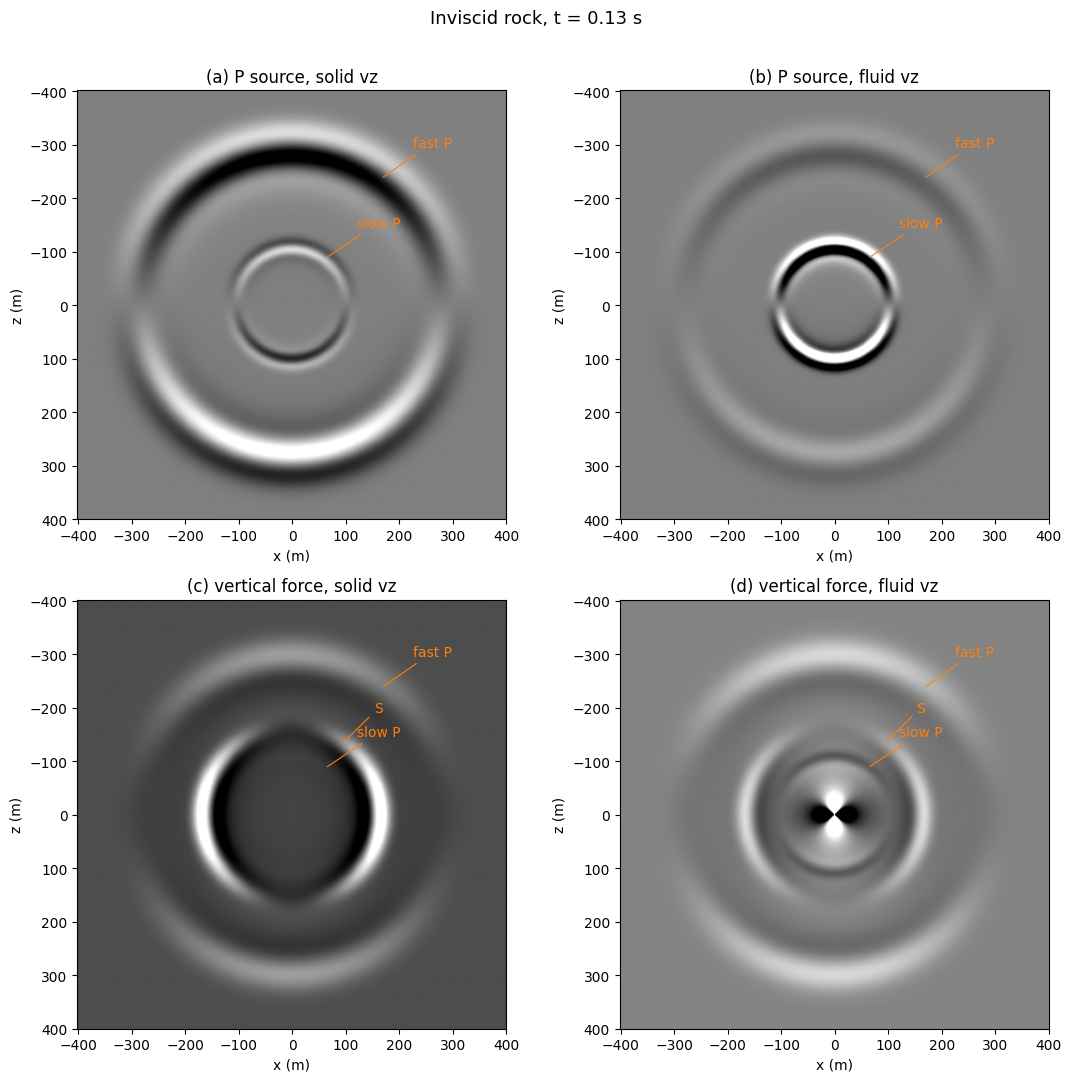

In [2]:
DX, DT, N, ABCN = 2.0, 2e-4, 401, 40
IT = 650                                          # snapshot step: 0.13 s
NT = IT + 1
TT = np.arange(NT)*DT
CENTRE = np.array([[N//2, N//2]])
DUMMY = np.array([[[N//2, N//2]]])

def props(fields_list, shape, dx, dt, nt, abcn=ABCN, free_surface=False, receivers=("vz",), snapshots=True):
    extra = dict(use_ckpt=False) if snapshots else {}
    return [PropTorch(Biot(device=DEV), shape=shape, dh=dx, dt=dt, nt=nt, source_type=list(f),
                      receiver_type=list(receivers), abcn=abcn, free_surface=free_surface, device=DEV,
                      backend="torch", impl="eager", **extra) for f in fields_list]

def fields(c, shape):
    # eight coefficient arrays on the device (scalars filled to the grid)
    return [x.float().to(DEV) if torch.is_tensor(x) and x.dim() else torch.full(shape, float(x), dtype=torch.float32, device=DEV)
            for x in c]

def run(ps, scales, wavelet, c, shape, src, rec, steps=None):
    # sum over the source parts; records (nt, nrec, nrecfields) and snapshots of (vz, qz)
    ms = fields(c, shape)
    vmax = biot_fast_p_velocity([float(x) if not torch.is_tensor(x) else x for x in c])
    rec_sum, snap_sum = 0.0, 0.0
    for p, s in zip(ps, scales):
        kw = dict(return_wavefield=True, snapshot_times=steps) if steps is not None else {}
        with torch.no_grad():
            out = p(torch.from_numpy(wavelet*s).float(), src, rec, models=ms, max_vel=vmax, pml_freq=F0, **kw)
        r_, sn = (out if steps is not None else (out, None))
        rec_sum = rec_sum + r_[0].double().cpu().numpy()
        if steps is not None:
            names = list(p.wavefield_names); z0, x0 = p.pad[0], p.pad[2]
            snap_sum = snap_sum + sn[:, [names.index("vz"), names.index("qz")], 0, 0,
                                     z0:z0 + shape[0], x0:x0 + shape[1]].double().cpu().numpy()
    return rec_sum, snap_sum

def clip(a):
    # colour limits from the signed 1st / 99th percentiles of the samples the wave has reached
    a = a[np.abs(a) > 1e-4*np.abs(a).max()]
    return np.percentile(a, [1, 99])

t0 = time.time()
P_SRC = props([["sxx", "szz"], ["p"]], (N, N), DX, DT, NT)
F_SRC = props([["vz"]], (N, N), DX, DT, NT)
rate = DT*np.gradient(S(TT), TT)/DX**2            # line source: the rate of the potential S(t)
_, snap_p = run(P_SRC, [1.0, -0.1/PHI], rate, coef, (N, N), CENTRE, DUMMY, [IT])
_, snap_f = run(F_SRC, [1.0], DT*S(TT)/DX**2, coef, (N, N), CENTRE, DUMMY, [IT])
print(f"four runs in {time.time() - t0:.0f} s")

ext = [-N//2*DX, N//2*DX, N//2*DX, -N//2*DX]
r = {k: (IT*DT - T0)*v for k, v in (("fast P", vf), ("S", vs), ("slow P", vsl))}
fig, axs = plt.subplots(2, 2, figsize=(11, 11))
for ax, (lab, a) in zip(axs.ravel(), [("(a) P source, solid vz", snap_p[0, 0]),
                                       ("(b) P source, fluid vz", snap_p[0, 0] + snap_p[0, 1]/PHI),
                                       ("(c) vertical force, solid vz", snap_f[0, 0]),
                                       ("(d) vertical force, fluid vz", snap_f[0, 0] + snap_f[0, 1]/PHI)]):
    lo, hi = clip(a)
    ax.imshow(a, cmap="gray", vmin=lo, vmax=hi, extent=ext)
    ax.set_title(lab, fontsize=12); ax.set_xlabel("x (m)"); ax.set_ylabel("z (m)")
for ax in axs.ravel():
    for name, rad in r.items():
        if name == "S" and ax in axs[0]:
            continue
        ang = np.radians(35)
        ax.annotate(name, xy=(rad*np.sin(ang), -rad*np.cos(ang)), xytext=(rad*np.sin(ang) + 60, -rad*np.cos(ang) - 60),
                    color="tab:orange", fontsize=10, arrowprops=dict(arrowstyle="-", color="tab:orange", lw=0.8))
fig.suptitle(f"Inviscid rock, t = {IT*DT:.2f} s", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.97]); plt.show()

## 3. Viscosity: when the slow wave stops propagating

The drag `b = η/κ` couples the fluid to the frame. Biot's characteristic frequency `f_c = b/(2π m)`
separates two regimes: well above it the slow wave propagates (attenuated), below it the fluid is
locked to the frame and the slow wave becomes a diffusion of pore pressure that never leaves the source.
Four rocks that differ only in `b`: inviscid, Dai's own value (f<sub>c</sub> = 2.5 Hz), f<sub>c</sub> = 58 Hz inside the
source band, and a Darcy-limit rock (f<sub>c</sub> ≈ 0.75 MHz).

The traces (solid `vz` 141 m from the P-type source) are compared with the analytic solution — the
frequency-domain Green's function of the viscous Biot medium, split into its fast and slow modes.

8 runs in 17 s
inviscid     f_c =          0 Hz   relative L2 error 0.0011
Dai's b      f_c =        2.5 Hz   relative L2 error 0.0010
f_c in band  f_c =       58.3 Hz   relative L2 error 0.0010
Darcy limit  f_c =    7.5e+05 Hz   relative L2 error 0.0010


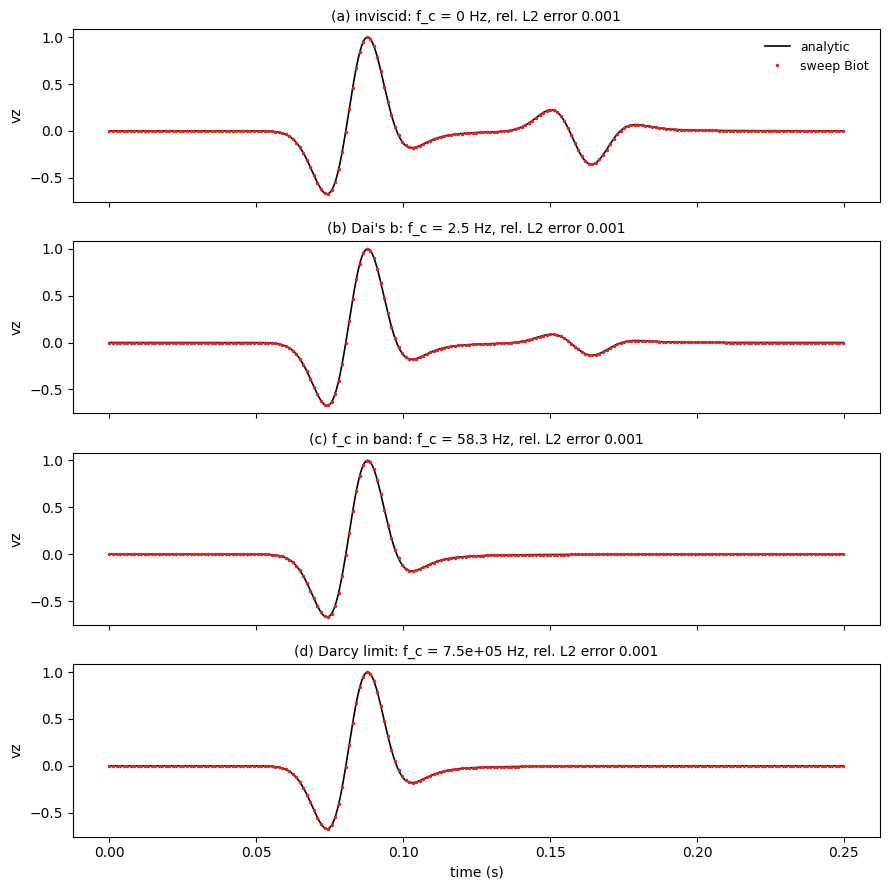

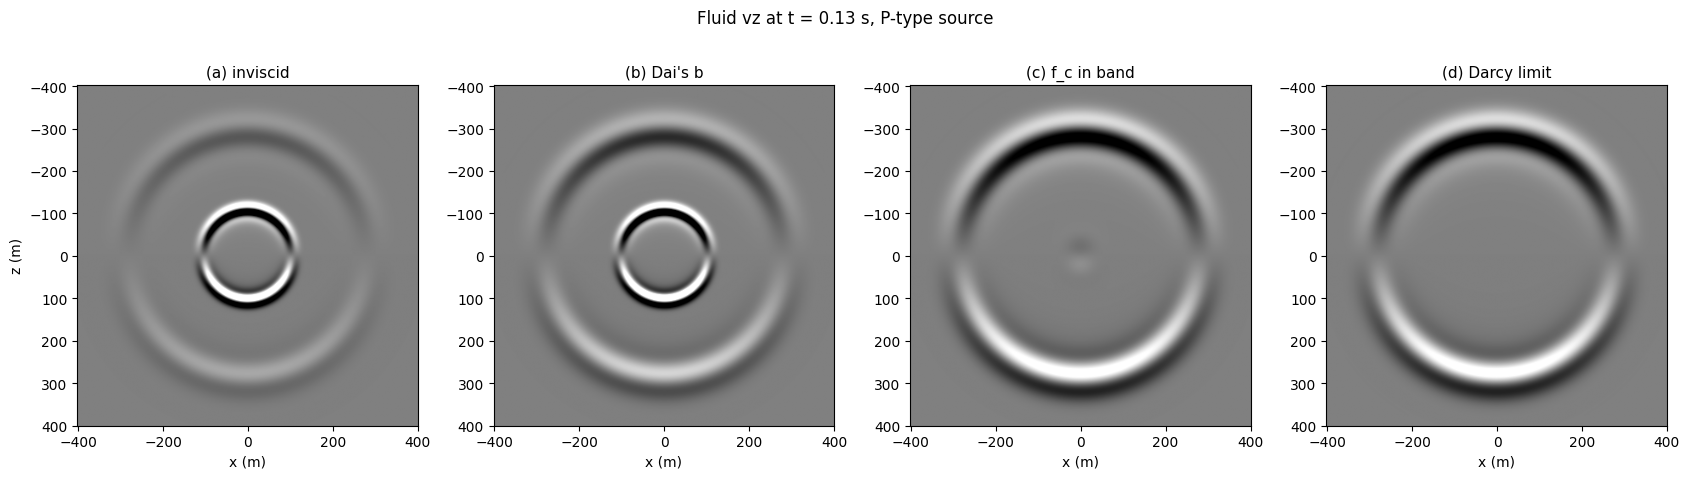

In [3]:
def analytic_vz(c, t, x, z, qpart=0.1, phi=PHI):
    # solid vz of a homogeneous viscous Biot medium for Dai's line source (exp(+i w t) Fourier transform):
    # K lap Psi + w^2 R(w) Psi = -F Phi with R_22 = m - i b / w, decomposed into the fast and slow modes
    h, mu, cc, bm, rho, rho_f, m, b = (float(v) for v in c)
    dt, nt = t[1] - t[0], len(t)
    n = 16*nt
    s_hat = np.fft.rfft(S(np.arange(n)*dt))
    w = 2*np.pi*np.fft.rfftfreq(n, dt)
    r = np.hypot(x, z)
    K = np.array([[h, cc], [cc, bm]], dtype=complex)
    F = np.array([1.0, qpart/phi], dtype=complex)
    v_hat = np.zeros_like(s_hat)
    for i in np.nonzero(np.abs(s_hat) > 1e-14*np.abs(s_hat).max())[0]:
        if w[i] == 0:
            continue
        s2, E = np.linalg.eig(np.linalg.solve(K, np.array([[rho, rho_f], [rho_f, m - 1j*b/w[i]]])))
        s = np.sqrt(s2); s = np.where(s.real < 0, -s, s)
        a = np.linalg.solve(K @ E, F)
        k = w[i]*s
        hk = hankel2e(1, k*r)*np.exp(-1j*k*r)              # scaled Hankel: the diffusive mode underflows cleanly
        v_hat[i] = -(w[i]/4)*(z/r)*s_hat[i]*np.sum(E[0]*a*k*hk)
    return np.fft.irfft(v_hat, n)[:nt]

REGIMES = [(0.0, "inviscid"), (3e3, "Dai's b"), (7e4, "f_c in band"), (9e8, "Darcy limit")]
DXT, DTT, NTT, OFF, PAD = 2.0, 2e-4, 1250, 50, 40
SH = (2*PAD + OFF + 1,)*2
TTT = np.arange(NTT)*DTT
T_SRC = props([["sxx", "szz"], ["p"]], SH, DXT, DTT, NTT, abcn=30, snapshots=False)
rate_t = DTT*np.gradient(S(TTT), TTT)/DXT**2
t0 = time.time()
traces, snaps = [], []
for bd, name in REGIMES:
    c = biot_from_biot_constants(**DAI1, b=bd, phi=PHI)
    num, _ = run(T_SRC, [1.0, -0.1/PHI], rate_t, c, SH, np.array([[PAD, PAD]]), np.array([[[PAD + OFF, PAD + OFF]]]))
    ana = analytic_vz(c, TTT, OFF*DXT, OFF*DXT + 0.5*DXT)          # vz sits half a cell below its row
    traces.append((name, float(c[7]/(2*np.pi*c[6])), num[:, 0, 0], ana))
    snaps.append(run(P_SRC, [1.0, -0.1/PHI], rate, c, (N, N), CENTRE, DUMMY, [IT])[1][0])
print(f"{2*len(REGIMES)} runs in {time.time() - t0:.0f} s")

fig, axs = plt.subplots(len(REGIMES), 1, figsize=(9, 9), sharex=True)
for k, (ax, (name, fc, num, ana)) in enumerate(zip(axs, traces)):
    err = np.linalg.norm(num - ana)/np.linalg.norm(ana)
    sc = np.abs(ana).max()
    ax.plot(TTT, ana/sc, "k-", lw=1.2, label="analytic")
    ax.plot(TTT[::6], num[::6]/sc, ".", color="tab:red", ms=3, label="sweep Biot")
    ax.set_title(f"({'abcd'[k]}) {name}: f_c = {fc:.3g} Hz, rel. L2 error {err:.3f}", fontsize=10)
    ax.set_ylabel("vz")
    print(f"{name:12s} f_c = {fc:10.3g} Hz   relative L2 error {err:.4f}")
axs[0].legend(frameon=False, fontsize=9); axs[-1].set_xlabel("time (s)")
fig.tight_layout(); plt.show()

fig, axs = plt.subplots(1, len(REGIMES), figsize=(17, 4.6))
for k, (ax, sn, (bd, name)) in enumerate(zip(axs, snaps, REGIMES)):
    a = sn[0] + sn[1]/PHI
    lo, hi = clip(a)
    ax.imshow(a, cmap="gray", vmin=lo, vmax=hi, extent=ext)
    ax.set_title(f"({'abcd'[k]}) {name}", fontsize=11); ax.set_xlabel("x (m)")
axs[0].set_ylabel("z (m)")
fig.suptitle(f"Fluid vz at t = {IT*DT:.2f} s, P-type source", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()

## 4. Two layers under an open-pore free surface (Dai et al. 1995, Figs 4–5)

Dai's two sandstones with their own damping, the interface 250 m deep, an explosion 12 m below the free
surface, 1 m grid. The top boundary is **open-pore**: traction-free total stress and *p* = 0, the fluid free
to drain (`free_surface=True`). Snapshots of the solid `vz`, then the record of a surface line.

upper layer: inviscid fast P 3210, slow P 1178, S 1792 m/s, f_c = 2.5 Hz
lower layer: inviscid fast P 4862, slow P 1737, S 2240 m/s, f_c = 437 Hz


6000 steps on 631x631 in 11 s


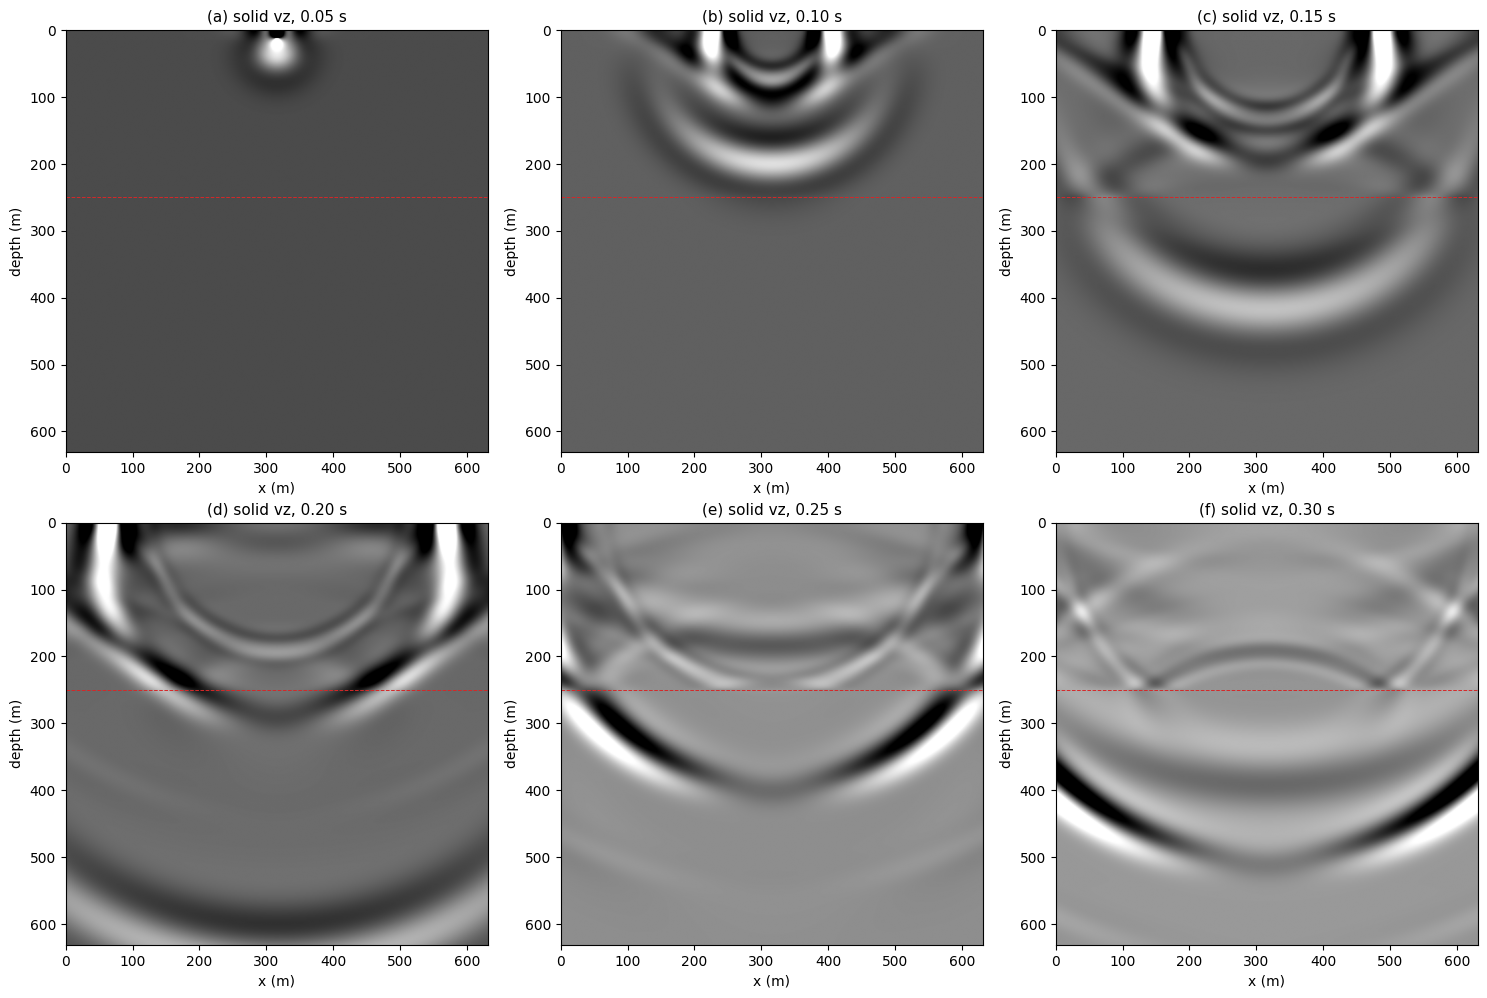

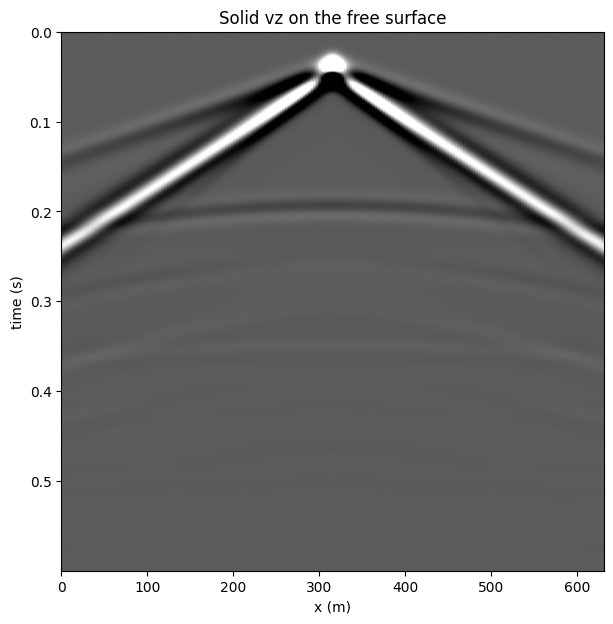

In [4]:
DX4, DT4, N4, NT4 = 1.0, 1e-4, 631, 6000
Z_INT = 250.0
SNAP_T = (0.05, 0.1, 0.15, 0.2, 0.25, 0.3)
c1 = biot_from_biot_constants(**DAI1, b=3e3, phi=PHI)
c2 = biot_from_biot_constants(**DAI2, b=7e5, phi=PHI)
lower = (torch.arange(N4, dtype=torch.float32)*DX4 >= Z_INT)[:, None].expand(N4, N4)
c_layers = [torch.where(lower, torch.tensor(float(b_)), torch.tensor(float(a_))) for a_, b_ in zip(c1, c2)]
for name, cc in (("upper", c1), ("lower", c2)):
    print(f"{name} layer: inviscid fast P {biot_wave_velocities(cc)[0]:.0f}, slow P {biot_wave_velocities(cc)[1]:.0f}, "
          f"S {biot_wave_velocities(cc)[2]:.0f} m/s, f_c = {float(cc[7])/(2*np.pi*float(cc[6])):.3g} Hz")
TT4 = np.arange(NT4)*DT4
REC4 = np.stack([np.arange(0, N4, 3), np.zeros(len(range(0, N4, 3)), int)], 1)[None]
FS = props([["sxx", "szz"]], (N4, N4), DX4, DT4, NT4, abcn=60, free_surface=True)
t0 = time.time()
rec4, snap4 = run(FS, [1.0], DT4*np.gradient(S(TT4), TT4)/DX4**2, c_layers, (N4, N4),
                  np.array([[315, 12]]), REC4, [int(round(t/DT4)) - 1 for t in SNAP_T])
print(f"6000 steps on {N4}x{N4} in {time.time() - t0:.0f} s")

fig, axs = plt.subplots(2, 3, figsize=(15, 10))
for k, (ax, t) in enumerate(zip(axs.ravel(), SNAP_T)):
    a = snap4[k, 0]
    lo, hi = clip(a)
    ax.imshow(a, cmap="gray", vmin=lo, vmax=hi, extent=[0, N4*DX4, N4*DX4, 0])
    ax.axhline(Z_INT, color="tab:red", lw=0.7, ls="--")
    ax.set_title(f"({'abcdef'[k]}) solid vz, {t:.2f} s", fontsize=11); ax.set_xlabel("x (m)"); ax.set_ylabel("depth (m)")
fig.tight_layout(); plt.show()

g = rec4[:, :, 0]
lo, hi = clip(g)
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(g, cmap="gray", vmin=lo, vmax=hi, extent=[0, N4*DX4, TT4[-1], 0], aspect="auto")
ax.set_xlabel("x (m)"); ax.set_ylabel("time (s)"); ax.set_title("Solid vz on the free surface", fontsize=12)
plt.show()

## 5. No relative flow is elastic

With `b → ∞` the fluid cannot move against the frame, and the Biot rock is an elastic solid with the
undrained (Gassmann) modulus: `Elastic` with `vp = √(H/ρ)`, `vs = √(μ/ρ)`. The same explosion in both:

In [5]:
c_lock = biot_from_biot_constants(**DAI1, b=1e16, phi=PHI)
h, mu, rho = float(c_lock[0]), float(c_lock[1]), float(c_lock[4])
rec_b, _ = run(props([["sxx", "szz"]], SH, DXT, DTT, NTT, abcn=30, snapshots=False), [1.0], rate_t, c_lock, SH,
               np.array([[PAD, PAD]]), np.array([[[PAD + OFF, PAD + OFF]]]))
el = PropTorch(Elastic(device=DEV), shape=SH, dh=DXT, dt=DTT, nt=NTT, source_type=["sxx", "szz"], receiver_type=["vz"],
               abcn=30, device=DEV, backend="torch", impl="eager")
with torch.no_grad():
    rec_e = el(torch.from_numpy(rate_t).float(), np.array([[PAD, PAD]]), np.array([[[PAD + OFF, PAD + OFF]]]),
               models=[torch.full(SH, v, dtype=torch.float32, device=DEV) for v in (np.sqrt(h/rho), np.sqrt(mu/rho), rho)],
               max_vel=biot_fast_p_velocity(c_lock), pml_freq=F0)[0].double().cpu().numpy()
print(f"Biot (b = 1e16) vs Elastic (undrained): relative L2 difference "
      f"{np.linalg.norm(rec_b[:, 0, 0] - rec_e[:, 0, 0])/np.linalg.norm(rec_e[:, 0, 0]):.1e}")

Biot (b = 1e16) vs Elastic (undrained): relative L2 difference 6.2e-06


## Notes

* **Time step.** The explicit update is limited by the *inviscid* fast P wave
  (`biot_fast_p_velocity`); the drag is integrated exactly, so a Darcy-limit rock needs no smaller step.
  The slow P wave is the shortest wavelength when `b` is small — resolve it like an S wave.
* **Free surface.** Only the top face, open-pore (σ<sub>zz</sub> = σ<sub>xz</sub> = *p* = 0); other faces and
  topography are refused.
* **Gradients.** `Biot` is eager-only and differentiable with respect to all eight coefficient models (and,
  through `biot_from_rock`, the rock properties); boundary saving is refused because the drag is
  dissipative, so gradients use checkpointing. Notebooks 38 and 39 use them for poroelastic sensitivity
  kernels and radiation patterns.

## Reference

Dai, N., Vafidis, A., & Kanasewich, E. R. (1995). Wave propagation in heterogeneous, porous media; a velocity-stress, finite-difference method. *Geophysics, 60*(2), 327–340. [doi:10.1190/1.1443769](https://doi.org/10.1190/1.1443769) — the two sandstones, the line source and the two-layer free-surface example reproduced here.